# Implementation of `txt2biocrnpyler` to Simulate Transcription-Factor-Based Biosensors

**Installing and Initializing Modules**: See the [README](https://github.com/usnistgov/txt2biocrnpyler/blob/master/README.md) documentation for additional details.

This notebook illustrates how to simulate a transcription-factor-based biosensor from *Programming Cell-free Biosensors with DNA Strand Displacement Circuits* ([Jung et al., *Nature Chemical Biology* 2022](https://www.nature.com/articles/s41589-021-00962-9)) in BioCRNpyler using `txt2biocrnpyler` to obtain an SBML `.xml` file from the provided ODEs. 

The workflow starts by converting the transcription-factor-based biosensor formatted chemical reactions to a BioCRNpyler script or SBML file using `txt2biocrnpyler`. The Pythin script generated is downloaded and can then be simulated as-is or modified to include upstream and downstream reactions prior to simulation. Alternatively, the  SBML file can be downloaded and simulated as-is using BioSCRAPE or any SBML simulator.

**Figure 3 Simulations:**
* [Figure 3B: Base Model Simulation](#Model-0:-Base-Model-Simulation)
* [Figure 3C: Extension with Downstream Translation](#Model-1:-Extension-with-Downstream-Translation)
* [Figure 3D: Extension with Upstream LacI Regulation](#Model-2:-Extension-with-Upstream-LacI-Regulation)

## Global variables, definitions, and dependencies

In [1]:
#General
import numpy as np

# #From bioscrape
# from bioscrape.simulator import py_simulate_model
# from bioscrape.types import Model
import matplotlib.pyplot as plt
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()
models_dir = (base_dir / 'models').as_posix()

In [2]:
# Simulate all models - example for 12 hours
timepoints = np.linspace(0,12,1001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (8.27, 6)

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.25, ymax = 25):
    fs = 22
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.xlabel('Time (h)',fontsize=22)
    plt.ylim(ymin,ymax)
    plt.xlim(0,12)

    plt.ylim(ymin,ymax)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)
    plt.legend(title="[tet]", frameon=False)

    # Save plot as svg
    plt.savefig(f'{figs_dir}/main_{fig_name}.svg')

colors=['#b3cde3','#8c96c6','#8856a7', '#810f7c']

# Model 0: Base Model Simulation

In [3]:
"""BioCRNpyler model auto-generated by txt2biocrnpyler from 'model'.

Run this file to rebuild the ChemicalReactionNetwork and write its SBML:
    python this_script.py
"""
from biocrnpyler import (
    ChemicalReactionNetwork,
    GeneralPropensity,
    ParameterEntry,
    Reaction,
    Species,
)

# --- Species ---------------------------------------------------------
crn_species = {
    'RNAP': Species('RNAP'),
    'D_unreg': Species('D_unreg'),
    'RD_unreg': Species('RD_unreg'),
    'InvR_U': Species('InvR_U'),
    'TetR': Species('TetR'),
    'D_tetO': Species('D_tetO'),
    'TetRD': Species('TetRD'),
    'tet': Species('tet'),
    'TetR_tet': Species('TetR_tet'),
    'RD_tetO': Species('RD_tetO'),
    'InvR_T': Species('InvR_T'),
    'Gated_T': Species('Gated_T'),
    'RQ': Species('RQ'),
    'SD': Species('SD'),
    'Q': Species('Q'),
}

# --- Parameters ------------------------------------------------------
parameters = {
    'k_m_tetO': ParameterEntry('k_m_tetO', 0.1),
    'k_m_unreg': ParameterEntry('k_m_unreg', 0.03),
    'k_bind': ParameterEntry('k_bind', 56.0),
    'k_unbind': ParameterEntry('k_unbind', 0.2),
    'k_SD_mis': ParameterEntry('k_SD_mis', 0.004),
    'k_SD_NOT': ParameterEntry('k_SD_NOT', 0.08),
    'k_rep_T': ParameterEntry('k_rep_T', 2.98),
    'k_derep_T': ParameterEntry('k_derep_T', 0.001),
    'k_ind_T': ParameterEntry('k_ind_T', 4.0),
    'k_unin_T': ParameterEntry('k_unin_T', 0.022),
}

# --- Reactions -------------------------------------------------------
reactions = [
    Reaction(
        inputs=[crn_species['RNAP'], crn_species['D_unreg']],
        outputs=[crn_species['RD_unreg']],
        propensity_type=GeneralPropensity(
            propensity_function='k_bind * RNAP * D_unreg - k_unbind * RD_unreg',
            propensity_species=[crn_species['D_unreg'], crn_species['RD_unreg'], crn_species['RNAP']],
            propensity_parameters=[parameters['k_bind'], parameters['k_unbind']],
        ),
    ),
    Reaction(
        inputs=[crn_species['RD_unreg']],
        outputs=[crn_species['InvR_U'], crn_species['RNAP'], crn_species['D_unreg']],
        propensity_type=GeneralPropensity(
            propensity_function='k_m_unreg * RD_unreg',
            propensity_species=[crn_species['RD_unreg']],
            propensity_parameters=[parameters['k_m_unreg']],
        ),
    ),
    Reaction(
        inputs=[crn_species['TetR'], crn_species['D_tetO']],
        outputs=[crn_species['TetRD']],
        propensity_type=GeneralPropensity(
            propensity_function='k_rep_T * TetR * D_tetO - k_derep_T * TetRD',
            propensity_species=[crn_species['D_tetO'], crn_species['TetR'], crn_species['TetRD']],
            propensity_parameters=[parameters['k_derep_T'], parameters['k_rep_T']],
        ),
    ),
    Reaction(
        inputs=[crn_species['TetR'], crn_species['tet']],
        outputs=[crn_species['TetR_tet']],
        propensity_type=GeneralPropensity(
            propensity_function='k_ind_T * TetR * tet - k_unin_T * TetR_tet',
            propensity_species=[crn_species['TetR'], crn_species['TetR_tet'], crn_species['tet']],
            propensity_parameters=[parameters['k_ind_T'], parameters['k_unin_T']],
        ),
    ),
    Reaction(
        inputs=[crn_species['RNAP'], crn_species['D_tetO']],
        outputs=[crn_species['RD_tetO']],
        propensity_type=GeneralPropensity(
            propensity_function='k_bind * RNAP * D_tetO - k_unbind * RD_tetO',
            propensity_species=[crn_species['D_tetO'], crn_species['RD_tetO'], crn_species['RNAP']],
            propensity_parameters=[parameters['k_bind'], parameters['k_unbind']],
        ),
    ),
    Reaction(
        inputs=[crn_species['RD_tetO']],
        outputs=[crn_species['InvR_T'], crn_species['RNAP'], crn_species['D_tetO']],
        propensity_type=GeneralPropensity(
            propensity_function='k_m_tetO * RD_tetO',
            propensity_species=[crn_species['RD_tetO']],
            propensity_parameters=[parameters['k_m_tetO']],
        ),
    ),
    Reaction(
        inputs=[crn_species['InvR_T'], crn_species['InvR_U']],
        outputs=[crn_species['Gated_T']],
        propensity_type=GeneralPropensity(
            propensity_function='k_SD_NOT * InvR_T * InvR_U',
            propensity_species=[crn_species['InvR_T'], crn_species['InvR_U']],
            propensity_parameters=[parameters['k_SD_NOT']],
        ),
    ),
    Reaction(
        inputs=[crn_species['InvR_U'], crn_species['RQ']],
        outputs=[crn_species['SD'], crn_species['Q']],
        propensity_type=GeneralPropensity(
            propensity_function='k_SD_mis * InvR_U * RQ',
            propensity_species=[crn_species['InvR_U'], crn_species['RQ']],
            propensity_parameters=[parameters['k_SD_mis']],
        ),
    ),
]

# --- Chemical Reaction Network ---------------------------------------
initial_concentration_dict = {
    crn_species['RNAP']: 0.1,
    crn_species['D_unreg']: 0.025,
    crn_species['TetR']: 5.0,
    crn_species['D_tetO']: 0.1,
    crn_species['tet']: 20.0,
    crn_species['RQ']: 5.0,
}

crn = ChemicalReactionNetwork(
    species=list(crn_species.values()),
    reactions=reactions,
    initial_concentration_dict=initial_concentration_dict,
)

if __name__ == "__main__":
    print(crn.pretty_print())
    crn.write_sbml_file(f"{models_dir}/jung2022_model_from_crn.xml")
    print("Wrote model_from_crn.xml")


Species(N = 15) = {
tet (@ 20.0),  TetR (@ 5.0),  RQ (@ 5.0),  RNAP (@ 0.1),  D_tetO (@ 0.1),  D_unreg (@ 0.025),  TetR_tet (@ 0),  TetRD (@ 0),  SD (@ 0),  RD_unreg (@ 0),  RD_tetO (@ 0),  Q (@ 0),  InvR_U (@ 0),  InvR_T (@ 0),  Gated_T (@ 0),  
}

Reactions (8) = [
0. RNAP+D_unreg --> RD_unreg
k_bind * RNAP * D_unreg - k_unbind * RD_unreg
  k_bind=56.0
  k_unbind=0.2

1. RD_unreg --> InvR_U+RNAP+D_unreg
k_m_unreg * RD_unreg
  k_m_unreg=0.03

2. TetR+D_tetO --> TetRD
k_rep_T * TetR * D_tetO - k_derep_T * TetRD
  k_derep_T=0.001
  k_rep_T=2.98

3. TetR+tet --> TetR_tet
k_ind_T * TetR * tet - k_unin_T * TetR_tet
  k_ind_T=4.0
  k_unin_T=0.022

4. RNAP+D_tetO --> RD_tetO
k_bind * RNAP * D_tetO - k_unbind * RD_tetO
  k_bind=56.0
  k_unbind=0.2

5. RD_tetO --> InvR_T+RNAP+D_tetO
k_m_tetO * RD_tetO
  k_m_tetO=0.1

6. InvR_T+InvR_U --> Gated_T
k_SD_NOT * InvR_T * InvR_U
  k_SD_NOT=0.08

7. InvR_U+RQ --> SD+Q
k_SD_mis * InvR_U * RQ
  k_SD_mis=0.004

]
Wrote model_from_crn.xml


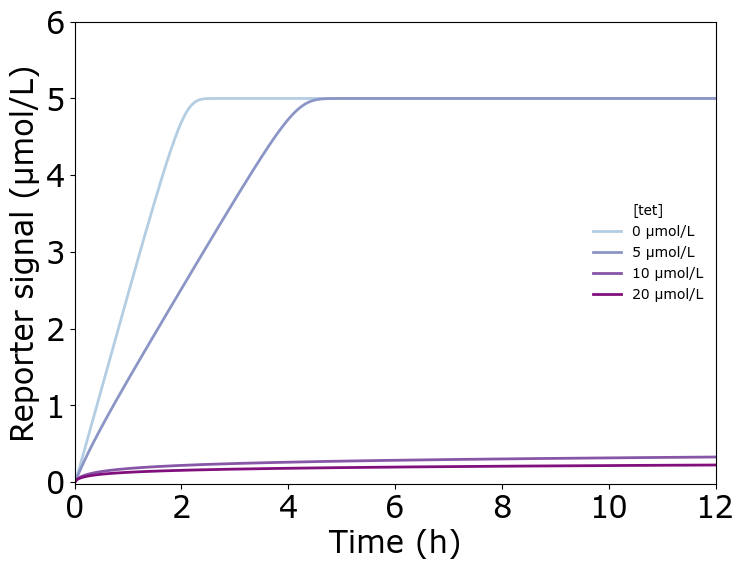

In [4]:
for tet_conc, color in zip([0, 5, 10, 20], colors):
    initial_concentration_dict.update({'tet':tet_conc})

    R = crn.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                             initial_condition_dict = initial_concentration_dict)

    # Results are in a Pandas Dictionary and can be accessed via string-names of species
    plt.plot(R['time']/3600, R['SD'], color=color, linewidth = 2, label = f"{tet_conc} μmol/L")

FormatPlot('Reporter signal (μmol/L)', 'Figure3_NOTgate', ymin = -0.02, ymax=6)

# Model 1: Extension with Downstream Translation

**Model 1= Model 0 + G{1, GFP} and TL**

Added reactions:
1. $D_{gate}$ + RNAP $\leftrightarrow$ $RD_{gate}$ $\rightarrow$ $D_{gate}$ + RNAP + Gate{1,GFP}$_{RNA}$
3. Gate{1,GFP}$_{RNA}$ + $InvR_v$ $\rightarrow$ $GFP_{RNA}$
4. $GFP_{RNA}$ $\rightarrow$ $GFP_{protein}$

***Note:** To simplify the modeling process, we took a shortcut by reusing existing species. Specifically, we effectively used R{1} in place of G{1,GFP} and translated from the product RNA `Q`.*

In [5]:
from biocrnpyler import *

# New species
D_GFPgate = DNAassembly('D_GFPgate', promoter='strong', transcript= 'RD_gate', protein= None)
RD_GFP = RNAassembly('RD_GFP', rbs = 'strong', protein = 'GFP')

# Mechanisms
mech_tx = Transcription_MM(rnap=crn_species['RNAP'])
mech_tl = SimpleTranslation()

tx_mechanism = {mech_tx.mechanism_type: mech_tx}
tl_mechanism = {mech_tl.mechanism_type: mech_tl}

# Dictionary parameters
parameters_THErrTL = {'ktx': parameters['k_m_unreg'].value, 
                      'kb': parameters['k_bind'].value, 
                      'ku': parameters['k_unbind'].value,
                      "ktl": .00005}

# Strand displacement
rxn1 = Reaction.from_massaction([D_GFPgate.transcript, crn_species['InvR_U']],[RD_GFP.transcript], k_forward = parameters['k_SD_mis'].value)

# Create mixture and crn
mixture_v1 = Mixture('THErr_Expression', components=[D_GFPgate,RD_GFP], 
                 parameters = parameters_THErrTL,
                 mechanisms = tx_mechanism | tl_mechanism)
crn_m1= mixture_v1.compile_crn()

# Add original species and reactions
crn_m1.add_species(crn.species)
crn_m1.add_reactions(crn.reactions + [rxn1])

# print(crn_m1.pretty_print())

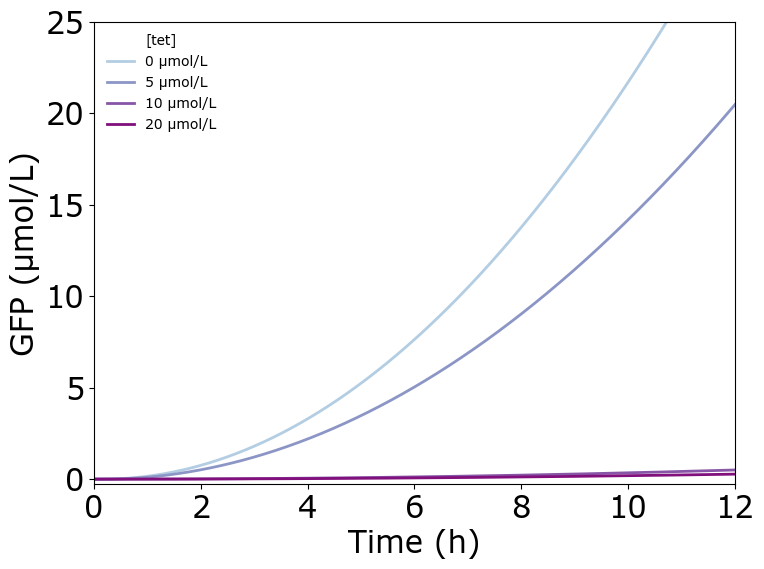

In [6]:
for tet_conc, color in zip([0, 5, 10, 20], colors):
    # Reset the initial concentration of the inducer to 0
    initial_concentration_dict.update({'tet': tet_conc, 'dna_D_GFPgate': 0.025, 'RQ': 0})

    R = crn_m1.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                             initial_condition_dict = initial_concentration_dict)

    # Plot each line and collect handles/ labels for the legend
    plt.plot(R['time'] /3600, R['protein_GFP'], color=color, linewidth = 2, label = f"{tet_conc} μmol/L")

# Format plot function call (assuming it sets some formatting properties)
FormatPlot('GFP (μmol/L)', 'Figure3_NOTgateTL')

# Model 2: Extension with Upstream LacI Regulation

**Model 2 = Model 1 + upstream LacI regulation**

Added reactions:

 * D_unreg + LacI $\leftrightarrow$ LacID
 * LacI + IPTG $\leftrightarrow$ LacI-IPTG

 ***Note:** Regulation to $D_{unreg}$ was introduced, but name of species was unchanged.*

In [7]:
# from biocrnpyler import ChemicalComplex, One_Step_Binding
LacI_DNA = ChemicalComplex(name='LacI_DNA', species=['LacI', crn_species['D_unreg']])
LacI_IPTG = ChemicalComplex(name='LacI_IPTG', species=['LacI', 'IPTG'])

parameters_LacI = {
    ParameterKey(mechanism = "binding", part_id = "LacI_DNA", name = "kb"):parameters['k_rep_T'].value,
    ParameterKey(mechanism = "binding", part_id = "LacI_DNA", name = "ku"):parameters['k_derep_T'].value,
    ParameterKey(mechanism = "binding", part_id = "LacI_IPTG", name = "kb"):parameters['k_ind_T'].value,
    ParameterKey(mechanism = "binding", part_id = "LacI_IPTG", name = "ku"):parameters['k_unin_T'].value,
    }

# Create mixture and crn
mixture=Mixture(
    components=[LacI_DNA, LacI_IPTG],
    mechanisms={'binding': One_Step_Binding()},
    parameters= parameters_LacI)
crn_m2 = mixture.compile_crn()

# Add previous species and reactions
crn_m2.add_species(crn_m1.species)
crn_m2.add_reactions(crn_m1.reactions )

# print(crn_m2.pretty_print())

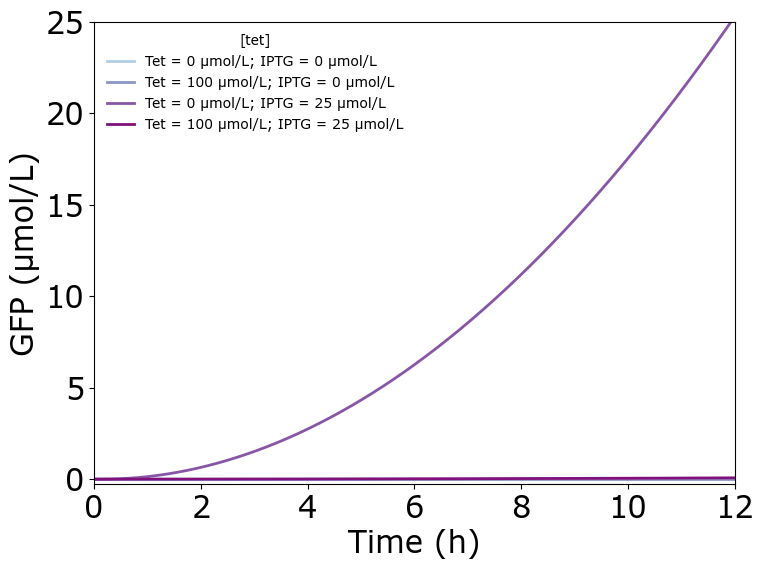

In [8]:
for tet_conc, tptg_conc, color in zip([0, 100, 0, 100], [0, 0, 25, 25], colors):
    # Reset the initial concentration of the inducer to 0
    initial_concentration_dict.update({'tet': tet_conc, 'IPTG': tptg_conc, 'LacI': 5, 'dna_D_GFPgate': 0.025, 'RQ': 0})

    R = crn_m2.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                             initial_condition_dict = initial_concentration_dict)

    # Plot each line and collect handles/ labels for the legend
    plt.plot(R['time'] /3600, R['protein_GFP'], color=color, linewidth=2, label=f"Tet = {tet_conc} μmol/L; IPTG = {tptg_conc} μmol/L")
plt.legend()

# Format plot function call (assuming it sets some formatting properties)
FormatPlot('GFP (μmol/L)', 'Figure3_NOTgateTL_reg')

# Computing environment

In [9]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

